# SC4002 Project Stage 1 #

The architect we are trying to produce is an encoder-only architect.

We first conduct the word inputs into vectors using a pretrained word2vector model GloVe, then we implement learned positional vectors and place it through 1 encoder layer.

Instead of the usual multi-head attention in the encoder, the encoder architect consists of 1 self-attention head instead, then it is pass through the first Add & Normalize, Feed-Forward Network, pass through the second Add & Normalize again and finally producing output through the linear and softmax functions after.

# Part A. Dataset and Preprocessing #

## A1. Imports ##

In [102]:
import json
import re
import numpy as np
import torch
import torch.nn as nn
import math
import torch.nn.functional as F
import random
import matplotlib.pyplot as plt
import time

from torch.utils.data import Dataset, DataLoader
from collections import Counter

## A2. Load MASSIVE dataset ##

In [103]:
dataset_path = "1.0/data/en-US.jsonl"

with open(dataset_path, 'r', encoding='utf-8') as f:
    data = [json.loads(line) for line in f]

print("Total examples:", len(data))
print("First example:")
print(data[0])

Total examples: 16521
First example:
{'id': '0', 'locale': 'en-US', 'partition': 'test', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at five am this week', 'annot_utt': 'wake me up at [time : five am] [date : this week]', 'worker_id': '1'}


## A3. Verify datasets and inspect labels ##

### Parition ###
Training(train): 11514

Validation(dev): 2033

Test(test): 2974 

In [104]:
split_counts = Counter(row["partition"] for row in data)

print(split_counts)

assert split_counts["train"] == 11514
assert split_counts["dev"] == 2033
assert split_counts["test"] == 2974

Counter({'train': 11514, 'test': 2974, 'dev': 2033})


### Inspect Unique Intent Labels ###

In [105]:
intent_labels = sorted(set(row["intent"] for row in data))

print("Number of unique intent labels:", len(intent_labels))
print("Intent labels:", intent_labels)

Number of unique intent labels: 60
Intent labels: ['alarm_query', 'alarm_remove', 'alarm_set', 'audio_volume_down', 'audio_volume_mute', 'audio_volume_other', 'audio_volume_up', 'calendar_query', 'calendar_remove', 'calendar_set', 'cooking_query', 'cooking_recipe', 'datetime_convert', 'datetime_query', 'email_addcontact', 'email_query', 'email_querycontact', 'email_sendemail', 'general_greet', 'general_joke', 'general_quirky', 'iot_cleaning', 'iot_coffee', 'iot_hue_lightchange', 'iot_hue_lightdim', 'iot_hue_lightoff', 'iot_hue_lighton', 'iot_hue_lightup', 'iot_wemo_off', 'iot_wemo_on', 'lists_createoradd', 'lists_query', 'lists_remove', 'music_dislikeness', 'music_likeness', 'music_query', 'music_settings', 'news_query', 'play_audiobook', 'play_game', 'play_music', 'play_podcasts', 'play_radio', 'qa_currency', 'qa_definition', 'qa_factoid', 'qa_maths', 'qa_stock', 'recommendation_events', 'recommendation_locations', 'recommendation_movies', 'social_post', 'social_query', 'takeaway_orde

In [106]:
for row in data[:5]:
    print("Input:", row["utt"])
    print("Intent:", row["intent"])
    print("Annotated:", row["annot_utt"])
    print()

Input: wake me up at five am this week
Intent: alarm_set
Annotated: wake me up at [time : five am] [date : this week]

Input: wake me up at nine am on friday
Intent: alarm_set
Annotated: wake me up at [time : nine am] on [date : friday]

Input: set an alarm for two hours from now
Intent: alarm_set
Annotated: set an alarm for [time : two hours from now]

Input: quiet
Intent: audio_volume_mute
Annotated: quiet

Input: olly quiet
Intent: audio_volume_mute
Annotated: olly quiet



## A4. Training-only Tokenization ##

In [107]:
# Use only the training data for building the vocabulary
train_data = [row for row in data if row["partition"] == "train"]

# Tokenize the text and build a vocabulary of unique tokens
def tokenize(text):
    pattern = r"\w+(?:['’]\w+)*|[^\w\s]" # Match words with optional apostrophes or non-word characters
    return [
        match.group().lower() # Convert to lowercase
        for match in re.finditer(pattern, text) # Use re.finditer to get match objects
    ]

## A5. Vocabulary Building ##

In [108]:
# Build a vocabulary of unique tokens and their counts
word_counts = Counter()

for row in train_data:
    tokens = tokenize(row["utt"])
    word_counts.update(tokens)

# Create a vocabulary dictionary mapping tokens to unique integer IDs
vocab = {
    "<PAD>": 0,
    "<UNK>": 1,
}

for word in sorted(word_counts):
    vocab[word] = len(vocab)

# Save the vocabulary to a JSON file
with open("vocab.json", 'w', encoding='utf-8') as f:
    json.dump(vocab, f, indent=2)

# Print Information
print("Training examples:", len(train_data))
print("Vocabulary size:", len(vocab))
print("Most common tokens:", word_counts.most_common(10))

# Test Sentence
sentence = "Wake me up at five am"

tokens = tokenize(sentence)
token_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

print("\nOriginal sentence:", sentence)
print("Tokens:", tokens)
print("Token IDs:", token_ids)

Training examples: 11514
Vocabulary size: 5294
Most common tokens: [('the', 4115), ('to', 2394), ('me', 1826), ('is', 1779), ('i', 1622), ('my', 1620), ('what', 1538), ('a', 1456), ('.', 1299), ('for', 1243)]

Original sentence: Wake me up at five am
Tokens: ['wake', 'me', 'up', 'at', 'five', 'am']
Token IDs: [5067, 2872, 4976, 281, 1720, 142]


## A6. GloVe Embeddings ##

In [109]:
embedding_dim = 100
vocab_size = len(vocab)

# Initialize embedding matrix
rng = np.random.default_rng(seed=42)  # Use a random number generator with a fixed seed for reproducibility

embedding_matrix = rng.normal(
    loc=0.0, 
    scale=0.05, 
    size=(vocab_size, embedding_dim)
).astype(np.float32)

# Padding token embedding (index 0) is a zero vector
embedding_matrix[vocab["<PAD>"]] = np.zeros(embedding_dim, dtype=np.float32)

# Load GloVe vectors matching the vocabulary
found_words = set()

with open("embeddings/glove.6B.100d.txt", 'r', encoding='utf-8') as f:
    for line in f:
        values = line.strip().split()
        word = values[0]

        if word not in vocab:
            continue

        vector = np.array(values[1:], dtype=np.float32)

        if len(vector) != embedding_dim:
            continue  # Skip if the vector dimension does not match

        word_id = vocab[word]
        embedding_matrix[word_id] = vector
        found_words.add(word)

print(f"Found embeddings for {len(found_words)} words.")

# Save the embedding matrix to a .npy file
np.save("embeddings/glove_matrix.npy", embedding_matrix)

# Print results
print("Embedding matrix shape:", embedding_matrix.shape)
print("Word matched with GloVe:", len(found_words))

total_words = vocab_size - 2

print(
    "Vocabulary coverage:",
    f"{len(found_words) / total_words * 100:.2f}% of the vocabulary matched with GloVe embeddings."
)

# Verify that the embedding matrix has been saved correctly
word = "wake"
word_id = vocab[word]

print("\nWord:", word)
print("Token ID:", word_id)
print("Embedding shape:", embedding_matrix[word_id].shape)
print("First 10 embedding values:", embedding_matrix[word_id][:10])

Found embeddings for 4914 words.
Embedding matrix shape: (5294, 100)
Word matched with GloVe: 4914
Vocabulary coverage: 92.86% of the vocabulary matched with GloVe embeddings.

Word: wake
Token ID: 5067
Embedding shape: (100,)
First 10 embedding values: [-0.081851 -0.19045   0.15264  -0.43457  -0.4726    0.17407  -0.26074
  0.052102 -0.28279  -0.2345  ]


## A6. Build the 60 intent IDs and 111 BIO IDs from training labels

1. Intent Mapping: 60 intent names <-> integer IDs
2. Slot Mapping: 55 slot types <-> 111 BIO-tag IDs

Both mappings will be build from the training data

### Intent Mapping ###

In [110]:
# Use only the training partition
train_data = [ row for row in data if row["partition"] == "train"]

# Extract unqiue intent labels
intent_labels = sorted(set(row["intent"] for row in train_data))

# Create mapping dictionaries for intent labels to IDs and vice versa
intent_to_id = {intent: idx for idx, intent in enumerate(intent_labels)}

id_to_intent = {idx: intent for intent, idx in intent_to_id.items()}

print("Number of intents:", len(intent_to_id))

print("First 10 intent mappings:")
for intent, idx in list(intent_to_id.items())[:10]:
    print(f"{idx}: {intent}")

Number of intents: 60
First 10 intent mappings:
0: alarm_query
1: alarm_remove
2: alarm_set
3: audio_volume_down
4: audio_volume_mute
5: audio_volume_other
6: audio_volume_up
7: calendar_query
8: calendar_remove
9: calendar_set


## A7. Build the 111 BIO IDs from training labels ##

### Slot Mapping ###

The MASSIVE dataset has 55 slot types.

In this case, we will utilize BIO tagging. For each slot type requires 2 possible labels: 55 x 2 + 1 = 111 BIO tags

This includes:
- B labels: 55
- I labels: 55
- O labels: 1

Each token's 100 dimensional vector goes through the same linear classifier Linear(100, 111). We then convert the logits to probabilities and choose the highest-scoring tag for every token

### Extract 55 slot types ###

In [111]:
slot_types = set()

for row in train_data:
    annotated = row["annot_utt"]

    # Extract label from [slot_type: slot_span]
    matches = re.findall(r"\[\s*([A-Za-z_][A-Za-z0-9_]*)\s*:", annotated)

    slot_types.update(matches)

slot_types = sorted(slot_types)

print("Number of slot types", len(slot_types))

print("\nSlot types:")
for slot in slot_types:
    print(slot)

Number of slot types 55

Slot types:
alarm_type
app_name
artist_name
audiobook_author
audiobook_name
business_name
business_type
change_amount
coffee_type
color_type
cooking_type
currency_name
date
definition_word
device_type
drink_type
email_address
email_folder
event_name
food_type
game_name
game_type
general_frequency
house_place
ingredient
joke_type
list_name
meal_type
media_type
movie_name
movie_type
music_album
music_descriptor
music_genre
news_topic
order_type
person
personal_info
place_name
player_setting
playlist_name
podcast_descriptor
podcast_name
radio_name
relation
song_name
sport_type
time
time_zone
timeofday
transport_agency
transport_descriptor
transport_name
transport_type
weather_descriptor


### Convert slot types into BIO tags ###

In [112]:
# Create BIO label vocabulary
bio_tags = ["O"]

for slot in slot_types:
    bio_tags.append(f"B-{slot}")
    bio_tags.append(f"I-{slot}")

# Create mappings
tag_to_id = {tag: idx for idx, tag in enumerate(bio_tags)}

id_to_tag = {idx: tag for tag, idx in tag_to_id.items()}

print("Number of BIO tags:", len(tag_to_id))

print("First 15 BIO tag mappings:")
for tag, idx in list(tag_to_id.items())[:15]:
    print(f"{idx}: {tag}")

Number of BIO tags: 111
First 15 BIO tag mappings:
0: O
1: B-alarm_type
2: I-alarm_type
3: B-app_name
4: I-app_name
5: B-artist_name
6: I-artist_name
7: B-audiobook_author
8: I-audiobook_author
9: B-audiobook_name
10: I-audiobook_name
11: B-business_name
12: I-business_name
13: B-business_type
14: I-business_type


## A8. Convert MASSIVE slot annotations to BIO tags

### Extract annotated spans ###

In [113]:
slot_pattern = re.compile(r"\[([A-Za-z_][A-Za-z0-9_]*)\s*:\s*([^\]]+)\]")

def extract_slot_spans(annotated_text):
    plain_text = ""
    spans = []
    cursor = 0

    for match in slot_pattern.finditer(annotated_text):
        # Copy the text before the match
        plain_text += annotated_text[cursor:match.start()]

        slot_type = match.group(1)
        slot_span = match.group(2)

        # Record the span and its corresponding slot type
        start = len(plain_text)
        plain_text += slot_span
        end = len(plain_text)

        spans.append((slot_type, start, end))
        cursor = match.end()

    plain_text += annotated_text[cursor:]  # Add any remaining text after the last match

    return plain_text, spans

In [114]:
example = (
    "wake me up at [time : five am] "
    "[date : this week]"
)

plain_text, spans = extract_slot_spans(example)

print("Reconstructed text:", plain_text)
print("Slot spans:", spans)

for slot_type, start, end in spans:
    print(slot_type, ":", plain_text[start:end])

Reconstructed text: wake me up at five am this week
Slot spans: [('time', 14, 21), ('date', 22, 31)]
time : five am
date : this week


### Convert spans into BIO labels ###

In [115]:
def convert_to_bio(utt, annot_utt):

    plain_text, spans = extract_slot_spans(annot_utt)

    # Ensure annotations match the original input
    if plain_text != utt:
        raise ValueError("Annotated text does not match the original utterance.")

    token_matches = list(re.finditer(r"\w+(?:['’]\w+)*|[^\w\s]", utt))

    tokens = [m.group() for m in token_matches]
    tags = ["O"] * len(tokens)

    for slot_type, start, end in spans:

        # Find tokens entirely inside the slot
        indices = [i for i, m in enumerate(token_matches) if m.start() >= start and m.end() <= end]

        if not indices:
            raise ValueError("No tokens found for slot")

        # Verify exact token-span alignment
        if (token_matches[indices[0]].start() != start or
            token_matches[indices[-1]].end() != end):
            raise ValueError("Tokenization does not align with slot span")

        for j, i in enumerate(indices):
            if tags[i] != "O":
                raise ValueError("Overlapping slots detected")

            prefix = "B" if j == 0 else "I"
            tags[i] = f"{prefix}-{slot_type}"

    return tokens, tags

In [116]:
sample = train_data[0]

tokens, tags = convert_to_bio(
    sample["utt"],
    sample["annot_utt"]
)

print("Utterance:", sample["utt"])
print("Intent:", sample["intent"])
print("Tokens:", tokens)
print("BIO tags:", tags)

assert len(tokens) == len(tags)
assert all(tag in tag_to_id for tag in tags)

print("BIO conversion verified!")

Utterance: wake me up at nine am on friday
Intent: alarm_set
Tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
BIO conversion verified!


## A9. Verify BIO alignment and sequence lengths across original splits ##

In [117]:
failures = []
sequence_lengths = []
split_counts = Counter()

for i, row in enumerate(data):
    try:
        tokens, tags = convert_to_bio(
            row["utt"],
            row["annot_utt"]
        )

        assert len(tokens) == len(tags)
        assert all(tag in tag_to_id for tag in tags)

        sequence_lengths.append(len(tokens))
        split_counts[row["partition"]] += 1

    except (ValueError, KeyError, AssertionError) as e:
        failures.append({
            "index": i,
            "utterance": row["utt"],
            "error": str(e)
        })

print("Successfully processed:", len(sequence_lengths))
print("Failed examples:", len(failures))
print("Successful examples by split:", split_counts)

if sequence_lengths:
    print("Maximum sequence length:", max(sequence_lengths))
    print("Average sequence length:",
          round(sum(sequence_lengths) / len(sequence_lengths), 2))

    print("Sequences longer than 64:",
          sum(length > 64 for length in sequence_lengths))

# Display any failures for investigation
for failure in failures[:5]:
    print(failure)

Successfully processed: 16521
Failed examples: 0
Successful examples by split: Counter({'train': 11514, 'test': 2974, 'dev': 2033})
Maximum sequence length: 61
Average sequence length: 7.01
Sequences longer than 64: 0


## A10. Create Dataset, Dynamic Padding and DataLoaders ##

### Prepare Dataset ###

In [118]:
class MassiveDataset(Dataset):
    def __init__(self, rows):
        self.examples = []

        for row in rows:
            # Convert annotations into BIO labels
            tokens, tags = convert_to_bio(
                row["utt"],
                row["annot_utt"]
            )

            # Convert tokens into vocabulary IDs, using <UNK> for unknown tokens
            input_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

            # Convert BIO labels into numerical ID
            slot_ids = [tag_to_id[tag] for tag in tags]

            # Convert intent label into numerical ID
            intent_id = intent_to_id[row["intent"]]

            # Preserve exact character offsets for later evaluation
            matches = list(re.finditer(r"\w+(?:['’]\w+)*|[^\w\s]", row["utt"]))

            offsets = [(m.start(), m.end()) for m in matches]

            assert len(tokens) == len(offsets)
            assert len(input_ids) == len(slot_ids)
            assert len(input_ids) <= max_length

            self.examples.append({
                "input_ids": input_ids,
                "slot_ids": slot_ids,
                "intent_id": intent_id,
                "tokens": tokens,
                "offsets": offsets,
                "utt": row["utt"]
            })

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]

### Padding Function ###

In [ ]:
# Collate function for DataLoader
def collate_fn(batch):

    batch_size = len(batch)

    # Pad only to the longest sequence in this batch
    max_len = max(len(example["input_ids"]) for example in batch)

    # Input IDs: PAD tokens have ID 0
    input_ids = torch.full(
        (batch_size, max_len), 
        vocab["<PAD>"], 
        dtype=torch.long
    )

    # Slot labels: -100 means ignore during loss
    slot_ids = torch.full(
        (batch_size, max_len), 
        -100, 
        dtype=torch.long
    )

    # Initialize attention mask: False for padding
    attention_mask = torch.zeros(
        (batch_size, max_len), 
        dtype=torch.bool
    )

    intent_ids = torch.tensor(
        [example["intent_id"] for example in batch],
        dtype=torch.long
    )

    # Copy actual tokens and labels into the padded tensors
    for i, example in enumerate(batch):
        length = len(example["input_ids"])

        input_ids[i,:length] = torch.tensor(example["input_ids"], dtype=torch.long)
        slot_ids[i,:length] = torch.tensor(example["slot_ids"], dtype=torch.long)
        attention_mask[i,:length] = True

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "slot_ids": slot_ids,
        "intent_ids": intent_ids,

        # Metadata for exact-span evaluation
        "utterances": [x["utt"] for x in batch],
        "offsets": [x["offsets"] for x in batch],
        "tokens": [x["tokens"] for x in batch]
    }

### DataLoaders ###

In [120]:
# Preserve original MASSIVE partitions
dev_data = [row for row in data if row["partition"] == "dev"]
test_data = [row for row in data if row["partition"] == "test"]

# Create dataset objects for each partition
train_dataset = MassiveDataset(train_data)
dev_dataset = MassiveDataset(dev_data)
test_dataset = MassiveDataset(test_data)

# Create DataLoaders for each partition
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(dev_dataset))
print("Test examples:", len(test_dataset))

Training examples: 11514
Validation examples: 2033
Test examples: 2974


In [121]:
batch = next(iter(train_loader))

print("Input IDs:", batch["input_ids"].shape)
print("Attention mask:", batch["attention_mask"].shape)
print("Slot IDs:", batch["slot_ids"].shape)
print("Intent IDs:", batch["intent_ids"].shape)

print("\nFirst sentence:")
print(batch["utterances"][0])

print("\nFirst sentence attention mask:")
print(batch["attention_mask"][0].int())

print("\nFirst sentence slot labels:")
print(batch["slot_ids"][0])

Input IDs: torch.Size([32, 12])
Attention mask: torch.Size([32, 12])
Slot IDs: torch.Size([32, 12])
Intent IDs: torch.Size([32])

First sentence:
list college sports for tomorrow in tulsa

First sentence attention mask:
tensor([1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0], dtype=torch.int32)

First sentence slot labels:
tensor([   0,   37,   38,    0,   25,    0,   77, -100, -100, -100, -100, -100])


# Part B. Encoder-Only Architecture: One shared single-head Transformer encoder #

## Architecture Pipeline ##
1. GloVe embedding + learned positional embedding.
2. One set of Query/Key/Value projections. 1 scaled self-attention head with padding mask.
3. Residual Add & Norm -> Feed-Forward Network -> Residual Add & Norm.
4. Branch into intent logits [batch, 60] and slot BIO logits [batch, length, 111].

### B1. Encoder-only Model ###

In [ ]:
class SingleHeadAttentionEncoder(nn.Module):
    def __init__(self, glove_vectors, pad_id, max_positions, num_intents, num_bio_tags, ffn_dim=200):
        super().__init__()
        vectors = torch.as_tensor(glove_vectors, dtype=torch.float32).clone()
        d_model = vectors.size(1) # 100 for GloVe 100d
        self.d_model = d_model
        self.max_positions = max_positions

        # Word vectors: initialized with GloVe and trainable
        self.word_embeddings = nn.Embedding.from_pretrained(vectors, freeze=False, padding_idx=pad_id)

        # Learned positional embeddings
        self.position_embeddings = nn.Embedding(max_positions, d_model)
        nn.init.normal_(self.position_embeddings.weight, mean=0.0, std=0.02)

        # Single-head attention parameters
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # Transformer encoder block: Add & Norm + Feedforward + Add & Norm
        self.layer_norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.ReLU(),
            nn.Linear(ffn_dim, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

        # The 2 classification heads shares the same encoder output
        self.intent_classifier = nn.Linear(d_model, num_intents)
        self.slot_classifier = nn.Linear(d_model, num_bio_tags)

    def forward(self, input_ids, attention_mask):

        # input_ids / attention_mask: (batch_size, seq_len)
        batch_size, seq_len = input_ids.shape

        if seq_len > self.max_positions:
            raise ValueError(f"Sequence length {seq_len} exceeds maximum {self.max_positions}")
        attention_mask = attention_mask.bool() # Ensure boolean type
        position = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)

        # Word embeddings and positional embeddings
        X = self.word_embeddings(input_ids) + self.position_embeddings(position)

        # Compute Q, K, V matrices for attention
        Q = self.W_q(X)
        K = self.W_k(X)
        V = self.W_v(X)
        
        # Compute attention scores and apply softmax
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_model)

        # Apply attention mask: set scores to -inf for padding tokens (Ignore them in softmax)
        scores = scores.masked_fill(~attention_mask.unsqueeze(1), float('-inf'))

        weights = torch.softmax(scores, dim=-1)
        attended  = torch.matmul(weights, V)

        # Add & Norm -> Feedforward -> Add & Norm
        H1 = self.layer_norm1(X + attended)
        H = self.norm2(H1 + self.ffn(H1))

        # Intent: masked mean pooling, so padding does not change the average
        valid = attention_mask.unsqueeze(-1).to(dtype=H.dtype)
        pooled = (H * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)
        intent_logits = self.intent_classifier(pooled) # (batch_size, num_intents)

        # Slot: per-token classification
        slot_logits = self.slot_classifier(H) # (batch_size, seq_len, num_bio_tags)
        return intent_logits, slot_logits


# Part C: Training, Validation, Checkpoint selection and Final Evaluation #

## C1: Training Setup ##

1. Creating of DataLoader
2. Initialize Model
3. Compute loss function

### Configurations: ###
- Seed: 42
- Epochs: 50
- Learning Rate: 1e-3
- Batch Size: 32

In [149]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

NUM_EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 32
CHECKPOINT_PATH = "model_checkpoint.pt"

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)

# Create DataLoader for training with reproducible shuffling
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    generator=shuffle_generator
)

# Initialize the model
model = SingleHeadAttentionEncoder(
    glove_vectors=embedding_matrix,
    pad_id=vocab["<PAD>"],
    max_positions=max_length,
    num_intents=len(intent_to_id),
    num_bio_tags=len(tag_to_id),
    ffn_dim=200,
)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
assert total_params <= 20_000_000

intent_criterion = nn.CrossEntropyLoss()
slot_criterion = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def compute_loss(intent_logits, slot_logits, intent_targets, slot_targets):
    # CrossEntropyLoss expects raw logits instead of probabilities, so no softmax is applied here.
    intent_loss = intent_criterion(intent_logits, intent_targets)
    slot_loss = slot_criterion(
        slot_logits.reshape(-1, slot_logits.size(-1)),
        slot_targets.reshape(-1)
    )
    total_loss = intent_loss + slot_loss
    
    return total_loss, intent_loss, slot_loss


print("Seed:", SEED)
print(f"Epochs: {NUM_EPOCHS}, batch size: {BATCH_SIZE}, learning rate: {LR}")
print(f"Total parameters: {total_params:,}, trainable: {trainable_params:,}")
print("Optimizer: Adam | Loss: intent cross-entropy + slot cross-entropy")
print("Training batches:", len(train_loader))

Total parameters: 624,071
Trainable parameters: 624,071
Seed: 42
Epochs: 30, batch size: 32, learning rate: 0.001
Total parameters: 624,071, trainable: 624,071
Optimizer: Adam | Loss: intent cross-entropy + slot cross-entropy
Training batches: 360


## C2: BIO decoding: prediction IDs to exact slot spans ##

### Convert BIO predictions back into exact [slot type: slot span] pairs ###

In [150]:
def decode_slot_pairs(tag_ids, utt, offsets):
    pairs = []
    active_type, start, end = None, None, None

    def finish():
        if active_type is not None:
            pairs.append((active_type, utt[start:end]))

    for i, (token_start, token_end) in enumerate(offsets):
        tag = id_to_tag[int(tag_ids[i])]
        if tag == "O":
            finish()
            active_type, start, end = None, None, None
            continue

        prefix, slot_type = tag.split("-", 1)

        # Invalid I-tags are treated as a new span
        if prefix == "B" or active_type != slot_type:
            finish()
            active_type, start, end = slot_type, token_start, token_end
        else:
            end = token_end

    finish()
    return pairs


# Sanity check of decoding without using model predictions
example_text = "wake me up at five am this week"
example_tokens, example_tags = convert_to_bio(
    example_text, "wake me up at [time : five am] [date : this week]"
)
example_offsets = [(m.start(), m.end()) for m in re.finditer(
    r"\w+(?:['’]\w+)*|[^\w\s]", example_text
)]
example_ids = [tag_to_id[t] for t in example_tags]
example_pairs = decode_slot_pairs(example_ids, example_text, example_offsets)
print("Decoded example:", example_pairs)
assert example_pairs == [("time", "five am"), ("date", "this week")]

Decoded example: [('time', 'five am'), ('date', 'this week')]


## C3: Evaluation ##

Validation model on DEV or evaluation final selected checkpoint on TEST

In [151]:
@torch.no_grad()
def evaluate(model, data_loader):
    model.eval()
    running_total = running_intent = running_slot = 0.0
    n_examples = correct_intent = 0
    tp = fp = fn = 0

    for batch in data_loader:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        slot_targets = batch["slot_ids"]
        intent_targets = batch["intent_ids"]

        intent_logits, slot_logits = model(input_ids, attention_mask)
        total_loss, intent_loss, slot_loss = compute_loss(
            intent_logits, slot_logits, intent_targets, slot_targets
        )
        bsz = input_ids.size(0)
        running_total += total_loss.item() * bsz
        running_intent += intent_loss.item() * bsz
        running_slot += slot_loss.item() * bsz
        n_examples += bsz

        predicted_intents = intent_logits.argmax(dim=-1)
        correct_intent += (predicted_intents == intent_targets).sum().item()

        predicted_slots = slot_logits.argmax(dim=-1)
        gold_slots = batch["slot_ids"].tolist()

        for i in range(bsz):
            offsets = batch["offsets"][i]
            utt = batch["utterances"][i]
            predicted_pairs = Counter(decode_slot_pairs(predicted_slots[i], utt, offsets))
            gold_pairs = Counter(decode_slot_pairs(gold_slots[i], utt, offsets))
            tp += sum((predicted_pairs & gold_pairs).values())
            fp += sum((predicted_pairs - gold_pairs).values())
            fn += sum((gold_pairs - predicted_pairs).values())

    if n_examples == 0:
        raise ValueError("No examples to evaluate.")
    denom = 2 * tp + fp + fn
    slot_micro_f1 = 100.0 * 2 * tp / denom if denom else 100.0
    return {
        "loss": running_total / n_examples,
        "intent_loss": running_intent / n_examples,
        "slot_loss": running_slot / n_examples,
        "intent_accuracy": 100.0 * correct_intent / n_examples,
        "slot_micro_f1": slot_micro_f1,
        "TP": tp,
        "FP": fp,
        "FN": fn
    }


## C4: Training Loop & Best Validation Checkpoint ##

In [152]:
history = []
best_score = float('-inf') # Initialize best score to negative infinity to ensure any valid score will be better.
best_epoch = None

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.perf_counter()
    model.train()

    # Initialize running totals for loss and example counts
    total_train = intent_train = slot_train = 0.0
    train_examples = 0

    # Training loop
    for batch in train_loader:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        intent_targets = batch["intent_ids"]
        slot_targets = batch["slot_ids"]

        optimizer.zero_grad(set_to_none=True)
        intent_logits, slot_logits = model(input_ids, attention_mask)
        loss, intent_loss, slot_loss = compute_loss(
            intent_logits, slot_logits, intent_targets, slot_targets
        )
        loss.backward()
        optimizer.step()

        # Update running totals for loss and example counts
        n = input_ids.size(0)
        train_examples += n
        total_train += loss.item() * n
        intent_train += intent_loss.item() * n
        slot_train += slot_loss.item() * n

    # No paramtere updates on DEV
    dev_result = evaluate(model, dev_loader)

    # Compute selection score as the average of intent accuracy and slot micro F1
    selection_score = (dev_result["intent_accuracy"] + dev_result["slot_micro_f1"]) / 2.0

    elapsed = time.perf_counter() - start

    record = {
        "epoch": epoch,
        "train_loss": total_train / train_examples,
        "train_intent_loss": intent_train / train_examples,
        "train_slot_loss": slot_train / train_examples,
        "val_loss": dev_result["loss"],
        "val_intent_loss": dev_result["intent_loss"],
        "val_slot_loss": dev_result["slot_loss"],
        "val_intent_accuracy": dev_result["intent_accuracy"],
        "val_slot_micro_f1": dev_result["slot_micro_f1"],
        "selection_score": selection_score,
        "elapsed_time_sec": elapsed
    }
    history.append(record)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {record['train_loss']:.4f} | "
        f"val loss {record['val_loss']:.4f} | "
        f"intent {record['val_intent_accuracy']:.2f}% | "
        f"slot F1 {record['val_slot_micro_f1']:.2f}% | "
        f"combined {selection_score:.2f}% | time {elapsed:.1f}s"
    )

    if selection_score > best_score:
        best_score = selection_score
        best_epoch = epoch
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "seed": SEED,
                "selection_score": best_score,
                "dev_intent_accuracy": dev_result["intent_accuracy"],
                "dev_slot_micro_f1": dev_result["slot_micro_f1"],
                "vocab": vocab,
                "intent_to_id": intent_to_id,
                "tag_to_id": tag_to_id
            },
            CHECKPOINT_PATH
        )

print(f"Best epoch: {best_epoch}")
print(f"Best combined DEV score: {best_score:.2f}%")
print(f"Saved checkpoint: {CHECKPOINT_PATH}")

Epoch 01/30 | train loss 2.9709 | val loss 1.5783 | intent 74.62% | slot F1 49.49% | combined 62.06% | time 4.1s
Epoch 02/30 | train loss 1.2413 | val loss 1.2208 | intent 80.67% | slot F1 57.33% | combined 69.00% | time 3.7s
Epoch 03/30 | train loss 0.8915 | val loss 1.0818 | intent 83.57% | slot F1 60.05% | combined 71.81% | time 3.5s
Epoch 04/30 | train loss 0.6828 | val loss 1.0520 | intent 83.57% | slot F1 60.18% | combined 71.87% | time 3.4s
Epoch 05/30 | train loss 0.5372 | val loss 1.0559 | intent 84.75% | slot F1 61.11% | combined 72.93% | time 5.4s
Epoch 06/30 | train loss 0.4345 | val loss 1.0786 | intent 84.16% | slot F1 61.65% | combined 72.90% | time 5.0s
Epoch 07/30 | train loss 0.3622 | val loss 1.1430 | intent 84.60% | slot F1 61.12% | combined 72.86% | time 3.6s
Epoch 08/30 | train loss 0.3030 | val loss 1.1985 | intent 82.88% | slot F1 62.41% | combined 72.65% | time 4.3s
Epoch 09/30 | train loss 0.2606 | val loss 1.2335 | intent 83.92% | slot F1 61.59% | combined 72

## C5: Plot Learning Curves ##

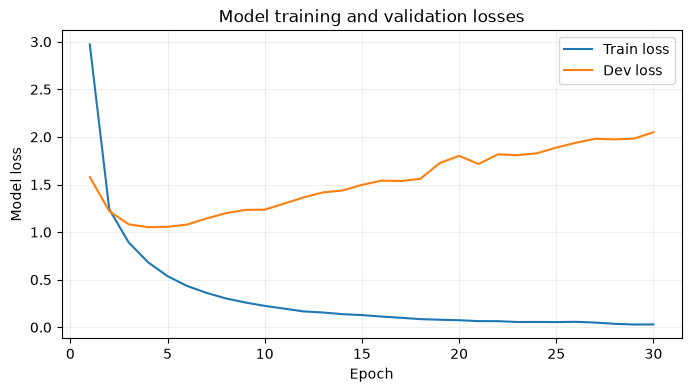

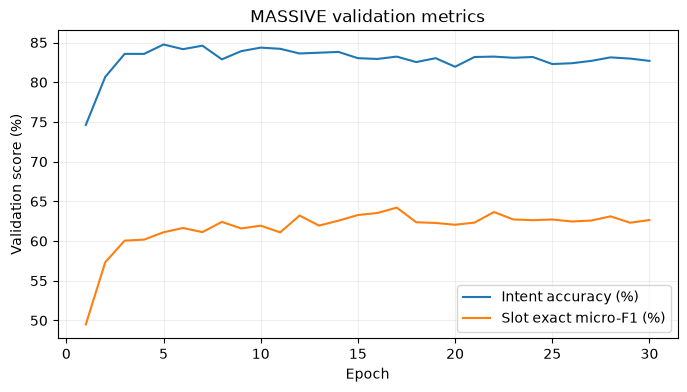

In [153]:
epoch_numbers = [x["epoch"] for x in history]
plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, [x["train_loss"] for x in history], label="Train loss")
plt.plot(epoch_numbers, [x["val_loss"] for x in history], label="Dev loss")
plt.xlabel("Epoch")
plt.ylabel("Model loss")
plt.title("Model training and validation losses")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, [x["val_intent_accuracy"] for x in history], label="Intent accuracy (%)")
plt.plot(epoch_numbers, [x["val_slot_micro_f1"] for x in history], label="Slot exact micro-F1 (%)")
plt.xlabel("Epoch")
plt.ylabel("Validation score (%)")
plt.title("MASSIVE validation metrics")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## C6: Reload Checkpoint and Final Evaluation ###

### Reload the BEST validation checkpoint and evaluate validation and test set. ###

In [154]:
checkpoint = torch.load(CHECKPOINT_PATH, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

final_dev = evaluate(model, dev_loader)
final_test = evaluate(model, test_loader)
reloaded_score = (final_dev["intent_accuracy"] + final_dev["slot_micro_f1"]) / 2.0

assert abs(reloaded_score - best_score) < 1e-5, "Reloaded model score does not match best DEV score."

print(f"Best checkpoint epoch: {checkpoint['epoch']} | Seed: {checkpoint['seed']}")
print(f"Validation: intent={final_dev['intent_accuracy']:.2f}% | "
      f"slot exact micro-F1={final_dev['slot_micro_f1']:.2f}%")
print(f"Test: intent={final_test['intent_accuracy']:.2f}% | "
      f"slot exact micro-F1={final_test['slot_micro_f1']:.2f}%")
print(f"Total parameters: {total_params:,} | Trainable: {trainable_params:,}")

Best checkpoint epoch: 17 | Seed: 42
Validation: intent=83.23% | slot exact micro-F1=64.21%
Test: intent=82.25% | slot exact micro-F1=58.19%
Total parameters: 624,071 | Trainable: 624,071


## C7: Predictions ##

In [155]:
@torch.no_grad()
def show_predictions(model, data_loader, num_examples=5):
    model.eval()
    batch = next(iter(data_loader))
    intent_logits, slot_logits = model(batch["input_ids"], batch["attention_mask"])
    predicted_intents = intent_logits.argmax(dim=-1).tolist()
    predicted_tags = slot_logits.argmax(dim=-1).tolist()

    for i in range(min(num_examples, len(predicted_intents))):
        print("Utterance:", batch["utterances"][i])
        print("Predicted intent:", id_to_intent[predicted_intents[i]])
        print("Predicted slots:", decode_slot_pairs(
            predicted_tags[i], batch["utterances"][i], batch["offsets"][i]
        ))
        print()

show_predictions(model, test_loader, num_examples=5)

Utterance: wake me up at five am this week
Predicted intent: alarm_set
Predicted slots: [('time', 'five am'), ('date', 'this week')]

Utterance: quiet
Predicted intent: audio_volume_mute
Predicted slots: []

Utterance: pink is all we need
Predicted intent: iot_hue_lightchange
Predicted slots: []

Utterance: and the darkness has fallen
Predicted intent: social_query
Predicted slots: [('person', 'darkness')]

Utterance: olly turn the lights off in the bedroom
Predicted intent: iot_hue_lightoff
Predicted slots: [('house_place', 'bedroom')]



In [136]:
examples_to_check = [
    "quiet",
    "pink is all we need",
    "and the darkness has fallen",
    "olly turn the lights off in the bedroom"
]

for utterance in examples_to_check:
    matches = [
        row for row in data
        if row["utt"] == utterance
    ]

    print("\nUtterance:", utterance)

    if not matches:
        print("Not found in MASSIVE dataset")
        continue

    for row in matches:
        print("Split:", row["partition"])
        print("True intent:", row["intent"])
        print("True slots:", row["annot_utt"])


Utterance: quiet
Split: test
True intent: audio_volume_mute
True slots: quiet
Split: train
True intent: audio_volume_mute
True slots: quiet

Utterance: pink is all we need
Split: test
True intent: iot_hue_lightchange
True slots: [color_type : pink] is all we need

Utterance: and the darkness has fallen
Split: test
True intent: iot_hue_lighton
True slots: and the darkness has fallen

Utterance: olly turn the lights off in the bedroom
Split: test
True intent: iot_hue_lightoff
True slots: olly turn the lights off in the [house_place : bedroom]


# Part D. Improvement 1: Rare-word UNK replacement + Regularization #

The baseline (Parts A–C) is left untouched so its results remain on record. This part only adds new cells.

### Weak points addressed ###
1. **`<UNK>` was never trained.** The vocabulary is built from the train split, so during training no token is ever `<UNK>`. Its embedding stays random, yet every unseen dev/test word (names, songs, places, the words slots are made of) maps to it.
   - **Fix (word dropout):** during training only, each token whose train frequency is `<= RARE_THRESHOLD` is replaced by `<UNK>` with probability `UNK_REPLACE_PROB`. The model learns a useful `<UNK>` vector and learns to tag slots from context.
2. **Heavy overfitting.** In the baseline, train loss reaches 0.03 while dev loss rises from 1.05 (epoch 4) to 2.05, with no regularization anywhere.
   - **Fix:** dropout on embeddings, attention weights, the FFN and residual branches, and before both classifier heads. **AdamW** with decoupled weight decay (not applied to embeddings, biases or LayerNorm), linear warmup + cosine LR decay, gradient clipping and early stopping on DEV.

The architecture is unchanged: 1 encoder layer, 1 self-attention head, GloVe 100d (trainable), same parameter count. Training uses the train split only, tuning/selection uses DEV only, and TEST is evaluated once at the end.

A follow-up experiment with frozen GloVe + a linear projection was tried and not adopted. See **D7** for the note.

## D1. Rare-word `<UNK>` replacement (training only) ##

`word_counts` comes from the train split (A5), so the rare-word set is built from train data only. The replacement happens inside a new training collate function. DEV and TEST loaders keep using the original `collate_fn`, so evaluation is unaffected.

- `RARE_THRESHOLD = 1`: words seen once in train are candidates. Set it to 2 to include words seen twice.
- `UNK_REPLACE_PROB = 0.5`: each time a rare token appears in a batch, it is replaced with probability 0.5, so the model still sees the real word half the time.

In [63]:
SEED_V2 = 42
RARE_THRESHOLD = 1        # words with train count <= this are eligible for <UNK> replacement
UNK_REPLACE_PROB = 0.5    # probability of replacing an eligible token in each batch

# Rare-word IDs, built from TRAIN counts only (word_counts from A5)
rare_word_ids = sorted(vocab[w] for w, c in word_counts.items() if c <= RARE_THRESHOLD)
rare_mask_lookup = torch.zeros(len(vocab), dtype=torch.bool)
rare_mask_lookup[rare_word_ids] = True

train_token_total = sum(word_counts.values())
rare_token_total = sum(c for c in word_counts.values() if c <= RARE_THRESHOLD)
print(f"Rare word types (count <= {RARE_THRESHOLD}): {len(rare_word_ids):,} / {len(word_counts):,} "
      f"({100 * len(rare_word_ids) / len(word_counts):.1f}% of vocab)")
print(f"Rare tokens: {rare_token_total:,} / {train_token_total:,} "
      f"({100 * rare_token_total / train_token_total:.2f}% of train tokens)")
print(f"Expected <UNK> rate during training: {100 * UNK_REPLACE_PROB * rare_token_total / train_token_total:.2f}% of tokens")

unk_generator = torch.Generator()
unk_generator.manual_seed(SEED_V2)

def collate_fn_word_dropout(batch):
    """Training-only collate: same padding as collate_fn, then rare tokens -> <UNK> with prob UNK_REPLACE_PROB."""
    out = collate_fn(batch)
    input_ids = out["input_ids"].clone()
    eligible = rare_mask_lookup[input_ids] & out["attention_mask"]
    coin = torch.rand(input_ids.shape, generator=unk_generator) < UNK_REPLACE_PROB
    input_ids[eligible & coin] = vocab["<UNK>"]
    out["input_ids"] = input_ids  # slot/intent labels are unchanged
    return out

# Sanity check on one batch
_check = collate_fn_word_dropout([train_dataset[i] for i in range(64)])
print("UNK tokens in sample batch:",
      int((_check["input_ids"] == vocab["<UNK>"]).sum()), "of", int(_check["attention_mask"].sum()))

Rare word types (count <= 1): 2,531 / 5,292 (47.8% of vocab)
Rare tokens: 2,531 / 81,120 (3.12% of train tokens)
Expected <UNK> rate during training: 1.56% of tokens
UNK tokens in sample batch: 2 of 383


## D2. Regularized Encoder-only Model ##

Same pipeline as B1 (GloVe + learned positions → 1 single-head self-attention → Add & Norm → FFN → Add & Norm → intent / slot heads), with dropout added at these points:

| Location | Rate |
|---|---|
| Word + position embeddings | `EMB_DROPOUT` |
| Attention weights (after softmax) | `ATTN_DROPOUT` |
| Inside FFN (after ReLU) | `HIDDEN_DROPOUT` |
| Attention and FFN outputs before each residual Add | `HIDDEN_DROPOUT` |
| Before intent and slot classifiers | `HIDDEN_DROPOUT` |

Dropout has no parameters, so the parameter count matches the baseline. It is disabled automatically in `model.eval()`, which `evaluate()` already calls.

In [64]:
class RegularizedSingleHeadEncoder(nn.Module):
    def __init__(self, glove_vectors, pad_id, max_positions, num_intents, num_bio_tags,
                 ffn_dim=200, emb_dropout=0.2, attn_dropout=0.1, hidden_dropout=0.2):
        super().__init__()
        vectors = torch.as_tensor(glove_vectors, dtype=torch.float32).clone()
        d_model = vectors.size(1)
        self.d_model = d_model
        self.max_positions = max_positions

        # Word vectors: initialized with GloVe and trainable (same as baseline)
        self.word_embeddings = nn.Embedding.from_pretrained(vectors, freeze=False, padding_idx=pad_id)

        # Learned positional embeddings
        self.position_embeddings = nn.Embedding(max_positions, d_model)
        nn.init.normal_(self.position_embeddings.weight, mean=0.0, std=0.02)

        # Single-head attention parameters
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # Dropout layers (no parameters)
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.attn_dropout = nn.Dropout(attn_dropout)
        self.hidden_dropout = nn.Dropout(hidden_dropout)

        # Add & Norm + FFN + Add & Norm
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.ReLU(),
            nn.Dropout(hidden_dropout),
            nn.Linear(ffn_dim, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

        # Two heads sharing the encoder output
        self.intent_classifier = nn.Linear(d_model, num_intents)
        self.slot_classifier = nn.Linear(d_model, num_bio_tags)

    def forward(self, input_ids, attention_mask):
        batch_size, seq_len = input_ids.shape
        if seq_len > self.max_positions:
            raise ValueError(f"Sequence length {seq_len} exceeds maximum {self.max_positions}")
        attention_mask = attention_mask.bool()
        position = torch.arange(seq_len, device=input_ids.device).unsqueeze(0).expand(batch_size, -1)

        # Embeddings + embedding dropout
        X = self.emb_dropout(self.word_embeddings(input_ids) + self.position_embeddings(position))

        # Single-head scaled dot-product attention with padding mask
        Q, K, V = self.W_q(X), self.W_k(X), self.W_v(X)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_model)
        scores = scores.masked_fill(~attention_mask.unsqueeze(1), float('-inf'))
        weights = self.attn_dropout(torch.softmax(scores, dim=-1))
        attended = torch.matmul(weights, V)

        # Add & Norm -> FFN -> Add & Norm (dropout on each residual branch)
        H1 = self.norm1(X + self.hidden_dropout(attended))
        H = self.norm2(H1 + self.hidden_dropout(self.ffn(H1)))

        # Intent: masked mean pooling
        valid = attention_mask.unsqueeze(-1).to(dtype=H.dtype)
        pooled = (H * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)
        intent_logits = self.intent_classifier(self.hidden_dropout(pooled))

        # Slot: per-token classification
        slot_logits = self.slot_classifier(self.hidden_dropout(H))
        return intent_logits, slot_logits

## D3. Training Setup (AdamW + warmup/cosine schedule) ##

### Configurations: ###
- Seed: 42 (reset so the comparison with the baseline is fair)
- Max epochs: 40, early stopping with patience 8 on the DEV selection score
- Learning rate: 1e-3, 1 epoch linear warmup, then cosine decay to 0
- Batch size: 32
- AdamW weight decay: 0.01 on Linear weights only. Embeddings, biases and LayerNorm are excluded, because decay would shrink GloVe vectors of words that rarely receive gradients.
- Gradient clipping: max norm 1.0
- Dropout: embeddings 0.2, attention 0.1, hidden/FFN/heads 0.2

The baseline objects (`model`, `optimizer`, `train_loader`, `history`) are not overwritten. Everything here uses a `_v2` suffix.

In [65]:
random.seed(SEED_V2)
np.random.seed(SEED_V2)
torch.manual_seed(SEED_V2)

NUM_EPOCHS_V2 = 40
PATIENCE_V2 = 8
LR_V2 = 1e-3
WEIGHT_DECAY_V2 = 0.01
WARMUP_EPOCHS_V2 = 1
GRAD_CLIP_V2 = 1.0
EMB_DROPOUT = 0.2
ATTN_DROPOUT = 0.1
HIDDEN_DROPOUT = 0.2
CHECKPOINT_PATH_V2 = "model_checkpoint_v2.pt"

shuffle_generator_v2 = torch.Generator()
shuffle_generator_v2.manual_seed(SEED_V2)
unk_generator.manual_seed(SEED_V2)  # reset after the D1 sanity check

# Training loader uses rare-word <UNK> replacement; DEV/TEST loaders are unchanged
train_loader_v2 = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn_word_dropout,
    num_workers=0,
    generator=shuffle_generator_v2
)

model_v2 = RegularizedSingleHeadEncoder(
    glove_vectors=embedding_matrix,
    pad_id=vocab["<PAD>"],
    max_positions=max_length,
    num_intents=len(intent_to_id),
    num_bio_tags=len(tag_to_id),
    ffn_dim=200,
    emb_dropout=EMB_DROPOUT,
    attn_dropout=ATTN_DROPOUT,
    hidden_dropout=HIDDEN_DROPOUT,
)

total_params_v2 = sum(p.numel() for p in model_v2.parameters())
trainable_params_v2 = sum(p.numel() for p in model_v2.parameters() if p.requires_grad)
assert total_params_v2 <= 20_000_000

# AdamW parameter groups: decay only Linear weight matrices
decay, no_decay = [], []
for name, param in model_v2.named_parameters():
    if not param.requires_grad:
        continue
    if param.ndim >= 2 and "embeddings" not in name:
        decay.append(param)
    else:
        no_decay.append(param)  # embeddings, biases, LayerNorm

optimizer_v2 = torch.optim.AdamW(
    [
        {"params": decay, "weight_decay": WEIGHT_DECAY_V2},
        {"params": no_decay, "weight_decay": 0.0},
    ],
    lr=LR_V2,
)

# Linear warmup then cosine decay, stepped once per batch
steps_per_epoch = len(train_loader_v2)
total_steps = NUM_EPOCHS_V2 * steps_per_epoch
warmup_steps = WARMUP_EPOCHS_V2 * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))

scheduler_v2 = torch.optim.lr_scheduler.LambdaLR(optimizer_v2, lr_lambda)

print("Seed:", SEED_V2)
print(f"Max epochs: {NUM_EPOCHS_V2} (patience {PATIENCE_V2}), batch size: {BATCH_SIZE}, peak LR: {LR_V2}")
print(f"AdamW weight decay: {WEIGHT_DECAY_V2} on {sum(p.numel() for p in decay):,} params, "
      f"none on {sum(p.numel() for p in no_decay):,} params")
print(f"Dropout: emb {EMB_DROPOUT}, attn {ATTN_DROPOUT}, hidden {HIDDEN_DROPOUT}")
print(f"Rare-word UNK: count <= {RARE_THRESHOLD}, p = {UNK_REPLACE_PROB}")
print(f"Total parameters: {total_params_v2:,} | Trainable: {trainable_params_v2:,}")

Seed: 42
Max epochs: 40 (patience 8), batch size: 32, peak LR: 0.001
AdamW weight decay: 0.01 on 87,100 params, none on 536,971 params
Dropout: emb 0.2, attn 0.1, hidden 0.2
Rare-word UNK: count <= 1, p = 0.5
Total parameters: 624,071 | Trainable: 624,071


## D4. Training Loop with Early Stopping ##

Same selection score as the baseline (mean of DEV intent accuracy and DEV slot micro-F1). Training stops if it doesn't improve for `PATIENCE_V2` epochs. The current LR is logged each epoch.

In [66]:
history_v2 = []
best_score_v2 = float('-inf')
best_epoch_v2 = None
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS_V2 + 1):
    start = time.perf_counter()
    model_v2.train()  # enables dropout (evaluate() switches back to eval mode)

    total_train = intent_train = slot_train = 0.0
    train_examples = 0

    for batch in train_loader_v2:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        intent_targets = batch["intent_ids"]
        slot_targets = batch["slot_ids"]

        optimizer_v2.zero_grad(set_to_none=True)
        intent_logits, slot_logits = model_v2(input_ids, attention_mask)
        loss, intent_loss, slot_loss = compute_loss(
            intent_logits, slot_logits, intent_targets, slot_targets
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_v2.parameters(), GRAD_CLIP_V2)
        optimizer_v2.step()
        scheduler_v2.step()

        n = input_ids.size(0)
        train_examples += n
        total_train += loss.item() * n
        intent_train += intent_loss.item() * n
        slot_train += slot_loss.item() * n

    # DEV only: no parameter updates
    dev_result = evaluate(model_v2, dev_loader)
    selection_score = (dev_result["intent_accuracy"] + dev_result["slot_micro_f1"]) / 2.0
    elapsed = time.perf_counter() - start
    current_lr = scheduler_v2.get_last_lr()[0]

    record = {
        "epoch": epoch,
        "lr": current_lr,
        "train_loss": total_train / train_examples,
        "train_intent_loss": intent_train / train_examples,
        "train_slot_loss": slot_train / train_examples,
        "val_loss": dev_result["loss"],
        "val_intent_loss": dev_result["intent_loss"],
        "val_slot_loss": dev_result["slot_loss"],
        "val_intent_accuracy": dev_result["intent_accuracy"],
        "val_slot_micro_f1": dev_result["slot_micro_f1"],
        "selection_score": selection_score,
        "elapsed_time_sec": elapsed
    }
    history_v2.append(record)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS_V2} | lr {current_lr:.2e} | "
        f"train loss {record['train_loss']:.4f} | "
        f"val loss {record['val_loss']:.4f} | "
        f"intent {record['val_intent_accuracy']:.2f}% | "
        f"slot F1 {record['val_slot_micro_f1']:.2f}% | "
        f"combined {selection_score:.2f}% | time {elapsed:.1f}s"
    )

    if selection_score > best_score_v2:
        best_score_v2 = selection_score
        best_epoch_v2 = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "model_state_dict": model_v2.state_dict(),
                "epoch": epoch,
                "seed": SEED_V2,
                "selection_score": best_score_v2,
                "dev_intent_accuracy": dev_result["intent_accuracy"],
                "dev_slot_micro_f1": dev_result["slot_micro_f1"],
                "vocab": vocab,
                "intent_to_id": intent_to_id,
                "tag_to_id": tag_to_id,
                "config": {
                    "rare_threshold": RARE_THRESHOLD,
                    "unk_replace_prob": UNK_REPLACE_PROB,
                    "emb_dropout": EMB_DROPOUT,
                    "attn_dropout": ATTN_DROPOUT,
                    "hidden_dropout": HIDDEN_DROPOUT,
                    "lr": LR_V2,
                    "weight_decay": WEIGHT_DECAY_V2,
                    "warmup_epochs": WARMUP_EPOCHS_V2,
                    "grad_clip": GRAD_CLIP_V2,
                    "max_epochs": NUM_EPOCHS_V2,
                },
            },
            CHECKPOINT_PATH_V2
        )
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE_V2:
            print(f"Early stopping: no DEV improvement for {PATIENCE_V2} epochs.")
            break

print(f"Best epoch: {best_epoch_v2}")
print(f"Best combined DEV score: {best_score_v2:.2f}%")
print(f"Saved checkpoint: {CHECKPOINT_PATH_V2}")

Epoch 01/40 | lr 1.00e-03 | train loss 5.0758 | val loss 2.2884 | intent 59.76% | slot F1 35.41% | combined 47.59% | time 5.4s
Epoch 02/40 | lr 9.98e-04 | train loss 2.0459 | val loss 1.4130 | intent 76.39% | slot F1 52.20% | combined 64.29% | time 5.2s
Epoch 03/40 | lr 9.94e-04 | train loss 1.4801 | val loss 1.1761 | intent 80.96% | slot F1 56.40% | combined 68.68% | time 5.0s
Epoch 04/40 | lr 9.85e-04 | train loss 1.2490 | val loss 1.1145 | intent 82.05% | slot F1 60.14% | combined 71.09% | time 5.0s
Epoch 05/40 | lr 9.74e-04 | train loss 1.0974 | val loss 1.0512 | intent 83.33% | slot F1 60.53% | combined 71.93% | time 5.0s
Epoch 06/40 | lr 9.60e-04 | train loss 0.9818 | val loss 1.0218 | intent 84.75% | slot F1 61.36% | combined 73.05% | time 5.0s
Epoch 07/40 | lr 9.43e-04 | train loss 0.9042 | val loss 1.0338 | intent 84.36% | slot F1 62.83% | combined 73.60% | time 5.0s
Epoch 08/40 | lr 9.23e-04 | train loss 0.8335 | val loss 1.0302 | intent 84.75% | slot F1 63.71% | combined 74.

## D5. Learning Curves: Baseline vs Improvement 1 ##

Dashed lines are the baseline (`history` from C4). Solid lines are Improvement 1. If the regularization works, the gap between train and dev loss should narrow and dev loss should stop climbing.

Note: with dropout and `<UNK>` replacement active, train loss is measured on noisier inputs, so it sits higher than the baseline's train loss. That is expected.

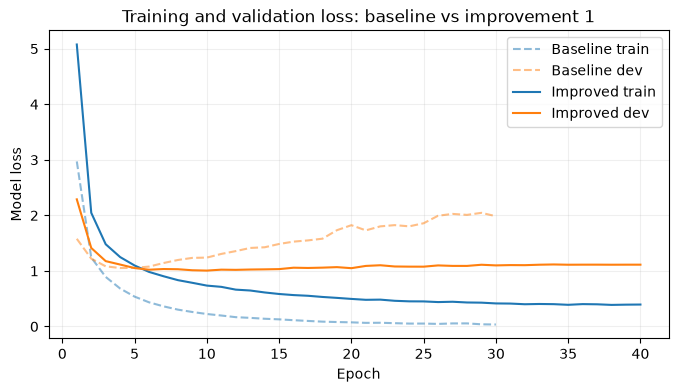

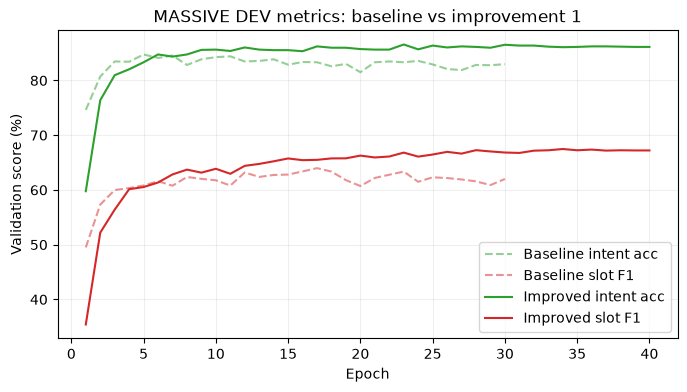

In [67]:
has_baseline_history = "history" in globals() and len(history) > 0
epochs_v2 = [x["epoch"] for x in history_v2]

plt.figure(figsize=(8, 4))
if has_baseline_history:
    epochs_v1 = [x["epoch"] for x in history]
    plt.plot(epochs_v1, [x["train_loss"] for x in history], "--", color="tab:blue", alpha=0.5, label="Baseline train")
    plt.plot(epochs_v1, [x["val_loss"] for x in history], "--", color="tab:orange", alpha=0.5, label="Baseline dev")
plt.plot(epochs_v2, [x["train_loss"] for x in history_v2], color="tab:blue", label="Improved train")
plt.plot(epochs_v2, [x["val_loss"] for x in history_v2], color="tab:orange", label="Improved dev")
plt.xlabel("Epoch")
plt.ylabel("Model loss")
plt.title("Training and validation loss: baseline vs improvement 1")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
if has_baseline_history:
    plt.plot(epochs_v1, [x["val_intent_accuracy"] for x in history], "--", color="tab:green", alpha=0.5, label="Baseline intent acc")
    plt.plot(epochs_v1, [x["val_slot_micro_f1"] for x in history], "--", color="tab:red", alpha=0.5, label="Baseline slot F1")
plt.plot(epochs_v2, [x["val_intent_accuracy"] for x in history_v2], color="tab:green", label="Improved intent acc")
plt.plot(epochs_v2, [x["val_slot_micro_f1"] for x in history_v2], color="tab:red", label="Improved slot F1")
plt.xlabel("Epoch")
plt.ylabel("Validation score (%)")
plt.title("MASSIVE DEV metrics: baseline vs improvement 1")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Some pointers:
- train loss and val loss have smaller gap between each other -> sign of less memorising
- val loss is leveled-off -> model stable, cannot gain from more epoch

## D6. Reload Best Checkpoint, Final Evaluation and Comparison ##

The best DEV checkpoint is reloaded and TEST is evaluated **once**. The baseline row uses `final_dev` / `final_test` from C6 if they are in memory. Otherwise it falls back to the recorded baseline numbers (DEV 83.23 / 64.21, TEST 82.25 / 58.19).

In [68]:
checkpoint_v2 = torch.load(CHECKPOINT_PATH_V2, weights_only=True)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"])
model_v2.eval()

final_dev_v2 = evaluate(model_v2, dev_loader)
final_test_v2 = evaluate(model_v2, test_loader)
reloaded_score_v2 = (final_dev_v2["intent_accuracy"] + final_dev_v2["slot_micro_f1"]) / 2.0
assert abs(reloaded_score_v2 - best_score_v2) < 1e-5, "Reloaded model score does not match best DEV score."

# Baseline reference numbers
if "final_dev" in globals() and "final_test" in globals():
    base = {
        "dev_intent": final_dev["intent_accuracy"], "dev_slot": final_dev["slot_micro_f1"],
        "test_intent": final_test["intent_accuracy"], "test_slot": final_test["slot_micro_f1"],
    }
else:
    base = {"dev_intent": 83.23, "dev_slot": 64.21, "test_intent": 82.25, "test_slot": 58.19}

impr = {
    "dev_intent": final_dev_v2["intent_accuracy"], "dev_slot": final_dev_v2["slot_micro_f1"],
    "test_intent": final_test_v2["intent_accuracy"], "test_slot": final_test_v2["slot_micro_f1"],
}

print(f"Best checkpoint epoch: {checkpoint_v2['epoch']} | Seed: {checkpoint_v2['seed']}")
print(f"Total parameters: {total_params_v2:,} | Trainable: {trainable_params_v2:,}\n")
print(f"{'Model':<28}{'DEV intent':>12}{'DEV slot F1':>13}{'TEST intent':>13}{'TEST slot F1':>14}")
print("-" * 80)
print(f"{'Baseline (C)':<28}{base['dev_intent']:>11.2f}%{base['dev_slot']:>12.2f}%"
      f"{base['test_intent']:>12.2f}%{base['test_slot']:>13.2f}%")
print(f"{'Improvement 1 (D)':<28}{impr['dev_intent']:>11.2f}%{impr['dev_slot']:>12.2f}%"
      f"{impr['test_intent']:>12.2f}%{impr['test_slot']:>13.2f}%")
print(f"{'Delta':<28}{impr['dev_intent'] - base['dev_intent']:>+11.2f} {impr['dev_slot'] - base['dev_slot']:>+11.2f} "
      f"{impr['test_intent'] - base['test_intent']:>+11.2f} {impr['test_slot'] - base['test_slot']:>+12.2f}")

print("\nSample TEST predictions:\n")
show_predictions(model_v2, test_loader, num_examples=5)

Best checkpoint epoch: 36 | Seed: 42
Total parameters: 624,071 | Trainable: 624,071

Model                         DEV intent  DEV slot F1  TEST intent  TEST slot F1
--------------------------------------------------------------------------------
Baseline (C)                      83.33%       63.98%       82.52%        58.75%
Improvement 1 (D)                 86.23%       67.37%       85.47%        64.53%
Delta                             +2.90       +3.39       +2.96        +5.78

Sample TEST predictions:

Utterance: wake me up at five am this week
Predicted intent: alarm_set
Predicted slots: [('time', 'five am'), ('date', 'this week')]

Utterance: quiet
Predicted intent: audio_volume_mute
Predicted slots: []

Utterance: pink is all we need
Predicted intent: iot_hue_lightchange
Predicted slots: [('color_type', 'pink')]

Utterance: and the darkness has fallen
Predicted intent: news_query
Predicted slots: []

Utterance: olly turn the lights off in the bedroom
Predicted intent: iot_hue_l

## D7. Experiment Note: Frozen GloVe + Linear Projection (tried, not adopted) ##

**What was tried:** on top of the Part D setup (rare-word `<UNK>` replacement, dropout, AdamW, warmup/cosine, gradient clipping, early stopping), the GloVe word vectors were **frozen**. A shared trainable `Linear(100, 100)` projection, initialised to identity, was added between the word vectors and the positional embeddings. `<UNK>` and the 379 train words without a GloVe vector stayed trainable through a small separate table. The vocabulary was still built from the train split only.

| | Unfrozen Part D (adopted) | Frozen GloVe + projection |
|---|---|---|
| Total / trainable params | 624,071 / 624,071 | 672,171 / 142,771 (529,400 frozen) |

**Motivation:** about 530k of the 624k baseline parameters are the embedding table, so fine-tuning GloVe lets the model memorize training words. Freezing was meant to stop that drift and reduce overfitting.

**Frozen run (seed 42, best epoch 33 of 40, no early stop):**

**Result 1:**

| Model | DEV intent | DEV slot F1 | TEST intent | TEST slot F1 |
|---|---|---|---|---|
| Baseline (C) | 83.33% | 63.98% | 82.52% | 58.75% |
| Frozen GloVe + projection | 84.90% | 61.97% | 83.09% | 58.62% |

**Result 2:**

Loss at the best epoch (33): train **0.850**, DEV **1.082**, so the gap is only ~0.23. The train loss also fell slowly the whole run (4.87 → 1.44 by epoch 5, still 0.83 at epoch 40) while DEV loss levelled off around 1.07.

**Evaluation of frozen vs original:**
- Good: **Smaller train/validation loss gap.** Overfitting was reduced, as intended.
- Bad:  **Training loss went up a lot.** The model could not fit the training data well. With word vectors fixed, one shared projection plus one encoder layer did not have enough capacity to adapt the embeddings to the task.
- Bad:  **Final intent accuracy and slot micro-F1 were both worse than the unfrozen Part D model.** DEV slot F1 even fell *below the baseline* (61.97% vs 63.98%), and TEST slot F1 did not improve (58.62% vs 58.75%).

**Conclusion:** freezing GloVe moved the model from overfitting to **underfitting**. The smaller gap came from losing training fit, not from better generalization. Part D therefore keeps **trainable (fine-tuned) GloVe embeddings**, and the overfitting is handled by dropout, AdamW weight decay, rare-word `<UNK>` replacement and early stopping instead.